In [44]:
# Intelligent Loan Risk Assessment Platform

## Exploratory Data Analysis (EDA)

### Objective

"""
The goal of this notebook is to understand the Home Credit loan dataset before designing the preprocessing pipeline and machine learning models.

This notebook covers:

- Dataset Overview
- Data Quality Assessment
- Missing Value Analysis
- Target Variable Analysis
- Feature Exploration
- Correlation Analysis
- Business Insights
- Preprocessing Decisions
"""

'\nThe goal of this notebook is to understand the Home Credit loan dataset before designing the preprocessing pipeline and machine learning models.\n\nThis notebook covers:\n\n- Dataset Overview\n- Data Quality Assessment\n- Missing Value Analysis\n- Target Variable Analysis\n- Feature Exploration\n- Correlation Analysis\n- Business Insights\n- Preprocessing Decisions\n'

In [45]:
# ==========================================================
# Standard Library Imports
# ==========================================================

import sys
from pathlib import Path

# ==========================================================
# Third-Party Imports
# ==========================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================================
# Local Imports
# ==========================================================

project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import DataLoader

# ==========================================================
# Notebook Settings
# ==========================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

plt.rcParams["figure.figsize"] = (10, 6)

sns.set_theme(style="whitegrid")

In [79]:
loader = DataLoader()

df = loader.load_training_data()

print("Dataset Loaded Successfully")

print(f"Shape: {df.shape}")

2026-08-06 21:07:55 | INFO | DataLoader | Loading dataset: /Users/prajwalkumarprathipati/Downloads/loan-risk-prediction/data/raw/application_train.csv
2026-08-06 21:07:57 | INFO | DataLoader | Successfully loaded dataset with shape (307511, 122)


Dataset Loaded Successfully
Shape: (307511, 122)


In [47]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [48]:
df.tail()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,225000.0,Unaccompanied,Working,Secondary / secondary special,Separated,With parents,0.032561,-9327,-236,-8456.0,-1982,NaN,1,1,0,1,0,0,Sales staff,1.0,1,1,THURSDAY,15,0,0,0,0,0,0,Services,0.145570,0.681632,NaN,0.2021,0.0887,0.9876,0.8300,0.0202,0.22,0.1034,0.6042,0.2708,0.0594,0.1484,0.1965,0.0753,0.1095,0.1008,0.0172,0.9782,0.7125,0.0172,0.0806,0.0345,0.4583,0.0417,0.0094,0.0882,0.0853,0.0,0.0125,0.2040,0.0887,0.9876,0.8323,0.0203,0.22,0.1034,0.6042,0.2708,0.0605,0.1509,0.2001,0.0757,0.1118,reg oper account,block of flats,0.2898,"Stone, brick",No,0.0,0.0,0.0,0.0,-273.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,225000.0,Unaccompanied,Pensioner,Secondary / secondary special,Widow,House / apartment,0.025164,-20775,365243,-4388.0,-4090,NaN,1,0,0,1,1,0,NaN,1.0,2,2,MONDAY,8,0,0,0,0,0,0,XNA,NaN,0.115992,NaN,0.0247,0.0435,0.9727,0.6260,0.0022,0.00,0.1034,0.0833,0.1250,0.0579,0.0202,0.0257,0.0000,0.0000,0.0252,0.0451,0.9727,0.6406,0.0022,0.0000,0.1034,0.0833,0.1250,0.0592,0.0220,0.0267,0.0,0.0000,0.0250,0.0435,0.9727,0.6310,0.0022,0.00,0.1034,0.0833,0.1250,0.0589,0.0205,0.0261,0.0000,0.0000,reg oper account,block of flats,0.0214,"Stone, brick",No,0.0,0.0,0.0,0.0,0.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,585000.0,Unaccompanied,Working,Higher education,Separated,House / apartment,0.005002,-14966,-7921,-6737.0,-5150,NaN,1,1,0,1,0,1,Managers,1.0,3,3,THURSDAY,9,0,0,0,0,1,1,School,0.744026,0.535722,0.218859,0.1031,0.0862,0.9816,0.7484,0.0123,0.00,0.2069,0.1667,0.2083,NaN,0.0841,0.9279,0.0000,0.0000,0.1050,0.0894,0.9816,0.7583,0.0124,0.0000,0.2069,0.1667,0.2

In [49]:
df.sample(5, random_state=42)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
245895,384575,0,Cash loans,M,Y,N,2,207000.0,465457.5,52641.0,418500.0,Unaccompanied,Commercial associate,Secondary / secondary special,Married,House / apartment,0.009630,-13297,-762,-637.0,-4307,19.0,1,1,0,1,0,0,Sales staff,4.0,2,2,THURSDAY,11,0,0,0,0,1,1,Business Entity Type 3,0.675878,0.604894,0.000527,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-2.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,1.0,0.0,1.0
98194,214010,0,Cash loans,F,Y,Y,0,247500.0,1281712.5,48946.5,1179000.0,Unaccompanied,Commercial associate,Higher education,Single / not married,House / apartment,0.006852,-14778,-1141,-1610.0,-4546,11.0,1,1,0,1,0,1,Managers,1.0,3,3,THURSDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.430827,0.425351,0.712155,0.0753,0.0568,0.9970,0.9592,0.1326,0.08,0.0517,0.4167,0.2917,0.0735,0.0601,0.0844,0.0058,0.1118,0.0756,0.0566,0.9940,0.9216,0.0523,0.0806,0.0345,0.3333,0.0417,0.0445,0.0652,0.0857,0.0,0.0000,0.0760,0.0568,0.9970,0.9597,0.1335,0.08,0.0517,0.4167,0.2917,0.0748,0.0611,0.0859,0.0058,0.1142,reg oper account,block of flats,0.0754,Monolithic,No,2.0,0.0,2.0,0.0,-1071.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,1.0,0.0,3.0
36463,142232,0,Cash loans,F,Y,N,0,202500.0,495000.0,39109.5,495000.0,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,0.035792,-17907,-639,-2507.0,-1461,4.0,1,1,1,1,0,0,Sales staff,2.0,2,2,TUESDAY,16,0,0,0,0,0,0,Self-employed,0.527239,0.531760,0.207964,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,0.0,5.0,0.0

In [50]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 536.7 MB


In [51]:
rows, cols = df.shape

print(f"Number of Rows    : {rows:,}")
print(f"Number of Columns : {cols}")


Number of Rows    : 307,511
Number of Columns : 122


In [52]:
dtype_summary = df.dtypes.value_counts().to_frame(name="Count")
dtype_summary

,Count
float64,65
int64,41
str,16


In [53]:
missing_values = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame(name="Missing Count")
)

missing_values["Missing Percentage"] = (
    missing_values["Missing Count"] / len(df)
) * 100

missing_values.head(20)

,Missing Count,Missing Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953


In [54]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


In [55]:
df.describe(include="object").T

/var/folders/xj/6xc_x48j50g124d8lj6dhv540000gn/T/ipykernel_78514/1274302342.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232
CODE_GENDER,307511,3,F,202448
FLAG_OWN_CAR,307511,2,N,202924
FLAG_OWN_REALTY,307511,2,Y,213312
NAME_TYPE_SUITE,306219,7,Unaccompanied,248526
NAME_INCOME_TYPE,307511,8,Working,158774
NAME_EDUCATION_TYPE,307511,5,Secondary / secondary special,218391
NAME_FAMILY_STATUS,307511,6,Married,196432
NAME_HOUSING_TYPE,307511,6,House / apartment,272868
OCCUPATION_TYPE,211120,18,Laborers,55186


In [56]:
duplicates = df.duplicated().sum()

print(f"Duplicate Rows: {duplicates}")

Duplicate Rows: 0


In [57]:
df["TARGET"].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [58]:
(
    df["TARGET"]
      .value_counts(normalize=True)
      .mul(100)
      .round(2)
      .rename("Percentage")
)

TARGET
0    91.93
1     8.07
Name: Percentage, dtype: float64

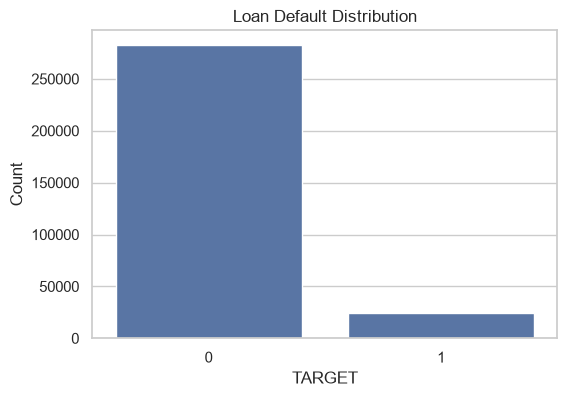

In [59]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="TARGET"
)

plt.title("Loan Default Distribution")

plt.xlabel("TARGET")

plt.ylabel("Count")

plt.show()

In [60]:
missing_values.head(20)

,Missing Count,Missing Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953


In [61]:
duplicates = df.duplicated().sum()

print(duplicates)

0


In [62]:
df["TARGET"].value_counts()

df["TARGET"].value_counts(normalize=True) * 100

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

In [63]:
feature_profile = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Count": df.isnull().sum().values,
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2).values,
    "Unique Values": df.nunique().values
})

feature_profile.head()

,Feature,Data Type,Missing Count,Missing Percentage,Unique Values
0,SK_ID_CURR,int64,0,0.0,307511
1,TARGET,int64,0,0.0,2
2,NAME_CONTRACT_TYPE,str,0,0.0,2
3,CODE_GENDER,str,0,0.0,3
4,FLAG_OWN_CAR,str,0,0.0,2


In [64]:
def classify_feature(dtype):
    if dtype == "object":
        return "Categorical"
    elif dtype.startswith("int") or dtype.startswith("float"):
        return "Numerical"
    else:
        return "Other"


feature_profile["Feature Type"] = feature_profile["Data Type"].apply(
    classify_feature
)

feature_profile.head()

,Feature,Data Type,Missing Count,Missing Percentage,Unique Values,Feature Type
0,SK_ID_CURR,int64,0,0.0,307511,Numerical
1,TARGET,int64,0,0.0,2,Numerical
2,NAME_CONTRACT_TYPE,str,0,0.0,2,Other
3,CODE_GENDER,str,0,0.0,3,Other
4,FLAG_OWN_CAR,str,0,0.0,2,Other


In [65]:
feature_profile = feature_profile[
    [
        "Feature",
        "Feature Type",
        "Data Type",
        "Missing Count",
        "Missing Percentage",
        "Unique Values",
    ]
]

feature_profile.head(10)

,Feature,Feature Type,Data Type,Missing Count,Missing Percentage,Unique Values
0,SK_ID_CURR,Numerical,int64,0,0.0,307511
1,TARGET,Numerical,int64,0,0.0,2
2,NAME_CONTRACT_TYPE,Other,str,0,0.0,2
3,CODE_GENDER,Other,str,0,0.0,3
4,FLAG_OWN_CAR,Other,str,0,0.0,2
5,FLAG_OWN_REALTY,Other,str,0,0.0,2
6,CNT_CHILDREN,Numerical,int64,0,0.0,15
7,AMT_INCOME_TOTAL,Numerical,float64,0,0.0,2548
8,AMT_CREDIT,Numerical,float64,0,0.0,5603
9,AMT_ANNUITY,Numerical,float64,12,0.0,13672


In [66]:
feature_profile["Feature Type"].value_counts()

Feature Type
Numerical    106
Other         16
Name: count, dtype: int64

In [67]:
feature_profile.sort_values(
    by="Missing Percentage",
    ascending=False
).head(20)

,Feature,Feature Type,Data Type,Missing Count,Missing Percentage,Unique Values
76,COMMONAREA_MEDI,Numerical,float64,214865,69.87,3202
48,COMMONAREA_AVG,Numerical,float64,214865,69.87,3181
62,COMMONAREA_MODE,Numerical,float64,214865,69.87,3128
70,NONLIVINGAPARTMENTS_MODE,Numerical,float64,213514,69.43,167
56,NONLIVINGAPARTMENTS_AVG,Numerical,float64,213514,69.43,386
84,NONLIVINGAPARTMENTS_MEDI,Numerical,float64,213514,69.43,214
86,FONDKAPREMONT_MODE,Other,str,210295,68.39,4
68,LIVINGAPARTMENTS_MODE,Numerical,float64,210199,68.35,736
54,LIVINGAPARTMENTS_AVG,Numerical,float64,210199,68.35,1868
82,LIVINGAPARTMENTS_MEDI,Numerical,float64,210199,68.35,1097


In [68]:
feature_profile.to_csv(
    "../docs/data_profile.csv",
    index=False
)

print("Feature profile saved successfully.")

Feature profile saved successfully.


In [69]:
categorical_columns = df.select_dtypes(include="object").columns.tolist()

print(f"Total Categorical Features: {len(categorical_columns)}")

categorical_columns

Total Categorical Features: 16


/var/folders/xj/6xc_x48j50g124d8lj6dhv540000gn/T/ipykernel_78514/4094545893.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns.tolist()


['NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'ORGANIZATION_TYPE',
 'FONDKAPREMONT_MODE',
 'HOUSETYPE_MODE',
 'WALLSMATERIAL_MODE',
 'EMERGENCYSTATE_MODE']

In [70]:
cardinality_df = pd.DataFrame({
    "Feature": categorical_columns,
    "Unique Categories": [
        df[col].nunique()
        for col in categorical_columns
    ],
    "Missing Percentage": [
        round(df[col].isnull().mean()*100,2)
        for col in categorical_columns
    ]
})

cardinality_df = cardinality_df.sort_values(
    by="Unique Categories",
    ascending=False
)

cardinality_df

,Feature,Unique Categories,Missing Percentage
11,ORGANIZATION_TYPE,58,0.00
9,OCCUPATION_TYPE,18,31.35
5,NAME_INCOME_TYPE,8,0.00
4,NAME_TYPE_SUITE,7,0.42
10,WEEKDAY_APPR_PROCESS_START,7,0.00
14,WALLSMATERIAL_MODE,7,50.84
7,NAME_FAMILY_STATUS,6,0.00
8,NAME_HOUSING_TYPE,6,0.00
6,NAME_EDUCATION_TYPE,5,0.00
12,FONDKAPREMONT_MODE,4,68.39


In [71]:
def cardinality_group(n):

    if n <= 2:
        return "Binary"

    elif n <= 10:
        return "Low"

    elif n <= 30:
        return "Medium"

    else:
        return "High"


cardinality_df["Cardinality"] = (
    cardinality_df["Unique Categories"]
    .apply(cardinality_group)
)

cardinality_df

,Feature,Unique Categories,Missing Percentage,Cardinality
11,ORGANIZATION_TYPE,58,0.00,High
9,OCCUPATION_TYPE,18,31.35,Medium
5,NAME_INCOME_TYPE,8,0.00,Low
4,NAME_TYPE_SUITE,7,0.42,Low
10,WEEKDAY_APPR_PROCESS_START,7,0.00,Low
14,WALLSMATERIAL_MODE,7,50.84,Low
7,NAME_FAMILY_STATUS,6,0.00,Low
8,NAME_HOUSING_TYPE,6,0.00,Low
6,NAME_EDUCATION_TYPE,5,0.00,Low
12,FONDKAPREMONT_MODE,4,68.39,Low


In [72]:
cardinality_df["Cardinality"].value_counts()

Cardinality
Low       10
Binary     4
High       1
Medium     1
Name: count, dtype: int64

In [73]:
cardinality_df.to_csv(
    "../docs/categorical_profile.csv",
    index=False
)

print("Categorical profile saved.")

Categorical profile saved.


In [74]:
recommendation_df = feature_profile.copy()

recommendation_df["Recommended Action"] = ""

In [75]:
def recommend_action(row):

    feature = row["Feature"]
    dtype = row["Feature Type"]
    missing = row["Missing Percentage"]
    unique = row["Unique Values"]

    # Target column
    if feature == "TARGET":
        return "Target Variable"

    # Numerical Features
    if dtype == "Numerical":

        if missing > 60:
            return "Investigate Before Dropping"

        elif missing > 0:
            return "Median Imputation"

        else:
            return "Keep"

    # Categorical Features
    else:

        if unique <= 2:
            return "Binary Encoding"

        elif unique <= 10:
            return "One-Hot Encoding"

        elif unique <= 30:
            return "Investigate Encoding"

        else:
            return "Frequency/Target Encoding Investigation"

In [76]:
recommendation_df["Recommended Action"] = (
    recommendation_df.apply(
        recommend_action,
        axis=1
    )
)

recommendation_df.head(20)

,Feature,Feature Type,Data Type,Missing Count,Missing Percentage,Unique Values,Recommended Action
0,SK_ID_CURR,Numerical,int64,0,0.00,307511,Keep
1,TARGET,Numerical,int64,0,0.00,2,Target Variable
2,NAME_CONTRACT_TYPE,Other,str,0,0.00,2,Binary Encoding
3,CODE_GENDER,Other,str,0,0.00,3,One-Hot Encoding
4,FLAG_OWN_CAR,Other,str,0,0.00,2,Binary Encoding
5,FLAG_OWN_REALTY,Other,str,0,0.00,2,Binary Encoding
6,CNT_CHILDREN,Numerical,int64,0,0.00,15,Keep
7,AMT_INCOME_TOTAL,Numerical,float64,0,0.00,2548,Keep
8,AMT_CREDIT,Numerical,float64,0,0.00,5603,Keep
9,AMT_ANNUITY,Numerical,float64,12,0.00,13672,Keep


In [77]:
recommendation_df["Recommended Action"].value_counts()

Recommended Action
Keep                                       47
Median Imputation                          42
Investigate Before Dropping                16
One-Hot Encoding                           10
Binary Encoding                             4
Target Variable                             1
Investigate Encoding                        1
Frequency/Target Encoding Investigation     1
Name: count, dtype: int64

In [78]:
recommendation_df.to_csv(
    "../docs/feature_recommendations.csv",
    index=False
)

print("Feature recommendation report created.")

Feature recommendation report created.
